In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
print("all libraries are imported successfully")

all libraries are imported successfully


In [2]:
import os
print(os.getcwd())

C:\Users\Laptop\OneDrive\Desktop\HR PROJECT


In [3]:
import os 
for file in os.listdir('.'):
    print(file)

.ipynb_checkpoints
HR-Attrition-analysis.xlsx
HR-Employee-Attrition.csv
HR_EMPLOYEES_ATTRITION_ANALYSIS.ipynb
HR_Employee_Attrition_Analysis.sql
Untitled.ipynb


In [4]:
df= pd.read_csv("HR-Employee-Attrition.csv")
print(df.head())

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

In [5]:
print("Dataset Shape:", df.shape)
print("total rows:", df.shape[0])
print("total column:", df.shape[1])


Dataset Shape: (1470, 35)
total rows: 1470
total column: 35


In [6]:
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [7]:
print("total Duplicate rows:",df.duplicated().sum())

total Duplicate rows: 0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [9]:
print("Attrition:",df['Attrition'].unique())
print("Gender:", df['Gender'].unique())
print("Department:", df['Department'].unique())
print("OverTime:", df['OverTime'].unique())


Attrition: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Department: <StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str
OverTime: <StringArray>
['Yes', 'No']
Length: 2, dtype: str


In [10]:
attrition_cleaned = df['Attrition'].astype(str).str.strip().str.lower()
total_employee = len(df)
employees_left = (df['Attrition']=='Yes').sum()
active_employees = (df['Attrition']=='No').sum()
attrition_rate = (employees_left/total_employee)*100
print("total employee:",total_employee)
print("employees left:",employees_left)
print("active_employees:",active_employees)
print("Attrition Rate:",round(attrition_rate,2), "%")

total employee: 1470
employees left: 237
active_employees: 1233
Attrition Rate: 16.12 %


In [11]:
print(df.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [12]:
print(df['Attrition'].head(10))

0    Yes
1     No
2    Yes
3     No
4     No
5     No
6     No
7     No
8     No
9     No
Name: Attrition, dtype: str


In [13]:
print(df['Attrition'].unique())

<StringArray>
['Yes', 'No']
Length: 2, dtype: str


In [14]:
print(df['Attrition'].astype(str).str.strip().str.lower().value_counts())

Attrition
no     1233
yes     237
Name: count, dtype: int64


In [15]:
print(type(df))
print(type(df['Attrition']))

<class 'pandas.DataFrame'>
<class 'pandas.Series'>


In [16]:
department_attrition = df.groupby('Department')['Attrition'].value_counts().unstack(fill_value=0)
print(department_attrition)

Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  828  133
Sales                   354   92


In [17]:
department_summary = df.groupby('Department').agg(total_employees= ('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum())) 
department_summary['Attrition_Rate'] = (department_summary['employees_left']/department_summary['total_employees']*100).round(2)
print(department_summary)

                        total_employees  employees_left  Attrition_Rate
Department                                                             
Human Resources                      63              12           19.05
Research & Development              961             133           13.84
Sales                               446              92           20.63


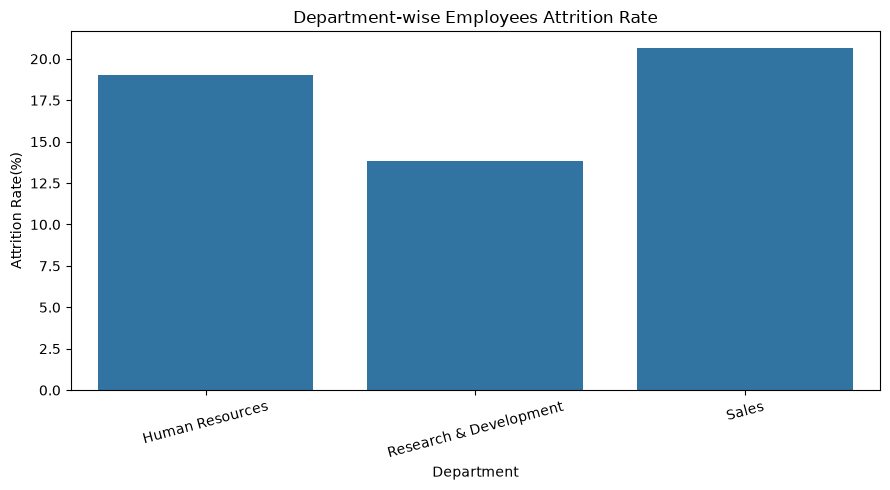

In [18]:
import seaborn as sns
plt.figure(figsize=(9,5))
sns.barplot(x= department_summary.index, y=department_summary['Attrition_Rate'])
plt.title('Department-wise Employees Attrition Rate')
plt.xlabel('Department')
plt.ylabel('Attrition Rate(%)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [19]:
df['Age_Group'] = pd.cut(df['Age'], bins=[18,24,35,45,55,61],labels=['18-24','25-35','35-44','45-54','55-60'], right= False)
age_summary = df.groupby('Age_Group', observed=False).agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
age_summary['Attrition_Rate'] = (age_summary['employees_left']/age_summary['total_employees']*100).round(2)
print(age_summary)                                                        

           total_employees  employees_left  Attrition_Rate
Age_Group                                                 
18-24                   71              31           43.66
25-35                  580             119           20.52
35-44                  505              51           10.10
45-54                  245              25           10.20
55-60                   69              11           15.94


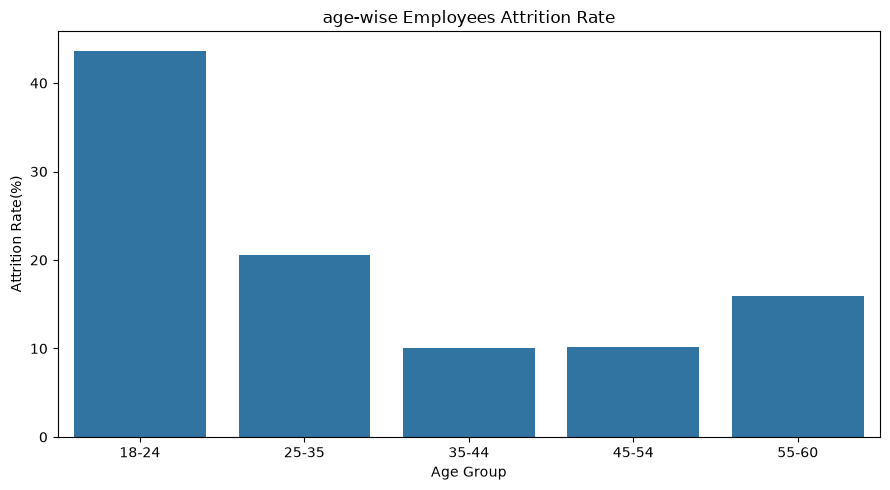

In [20]:
import seaborn as sns
plt.figure(figsize=(9,5))
sns.barplot(x= age_summary.index, y=age_summary['Attrition_Rate'])
plt.title('age-wise Employees Attrition Rate')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [21]:
gender_summary = df.groupby('Gender', observed=False).agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
gender_summary['Attrition_Rate'] = (gender_summary['employees_left']/gender_summary['total_employees']*100).round(2)
print(gender_summary)                                                        

        total_employees  employees_left  Attrition_Rate
Gender                                                 
Female              588              87           14.80
Male                882             150           17.01


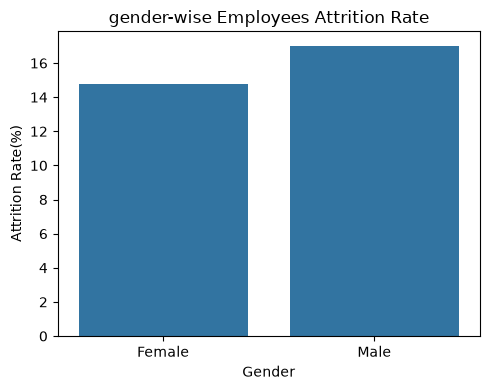

In [22]:
import seaborn as sns
plt.figure(figsize=(5,4))
sns.barplot(x= gender_summary.index, y=gender_summary['Attrition_Rate'])
plt.title('gender-wise Employees Attrition Rate')
plt.xlabel('Gender')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [27]:
JobRole_summary = df.groupby('JobRole').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
JobRole_summary['Attrition_Rate'] = (JobRole_summary['employees_left']/JobRole_summary['total_employees']*100).round(2)
print(JobRole_summary)                   

                           total_employees  employees_left  Attrition_Rate
JobRole                                                                   
Healthcare Representative              131               9            6.87
Human Resources                         52              12           23.08
Laboratory Technician                  259              62           23.94
Manager                                102               5            4.90
Manufacturing Director                 145              10            6.90
Research Director                       80               2            2.50
Research Scientist                     292              47           16.10
Sales Executive                        326              57           17.48
Sales Representative                    83              33           39.76


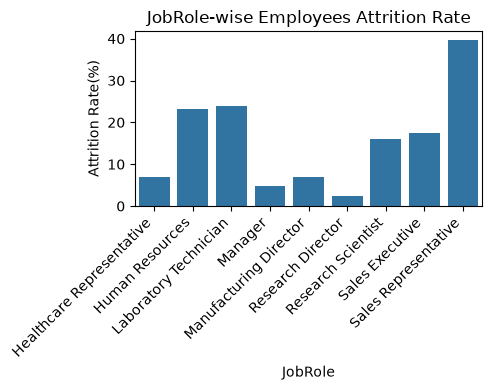

In [30]:
plt.figure(figsize=(5,4))
sns.barplot(x= JobRole_summary.index, y=JobRole_summary['Attrition_Rate'])
plt.title('JobRole-wise Employees Attrition Rate')
plt.xlabel('JobRole')
plt.ylabel('Attrition Rate(%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [33]:
income_summary = df.groupby ('Attrition') ['MonthlyIncome']. mean().round(2)
print(income_summary)

Attrition
No     6832.74
Yes    4787.09
Name: MonthlyIncome, dtype: float64


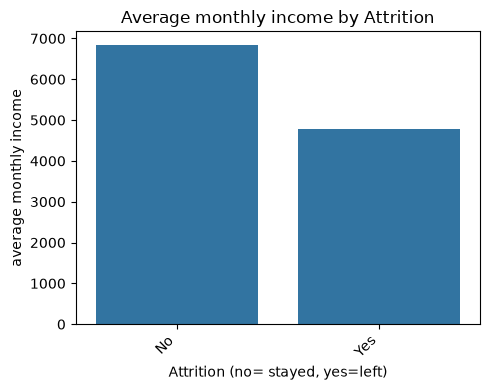

In [35]:
plt.figure(figsize=(5,4))
sns.barplot(x= income_summary.index, y=income_summary.values)
plt.title('Average monthly income by Attrition')
plt.xlabel('Attrition (no= stayed, yes=left)')
plt.ylabel('average monthly income')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [36]:
OverTime_summary = df.groupby('OverTime').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
OverTime_summary['Attrition_Rate'] = (OverTime_summary['employees_left']/OverTime_summary['total_employees']*100).round(2)
print(OverTime_summary)

          total_employees  employees_left  Attrition_Rate
OverTime                                                 
No                   1054             110           10.44
Yes                   416             127           30.53


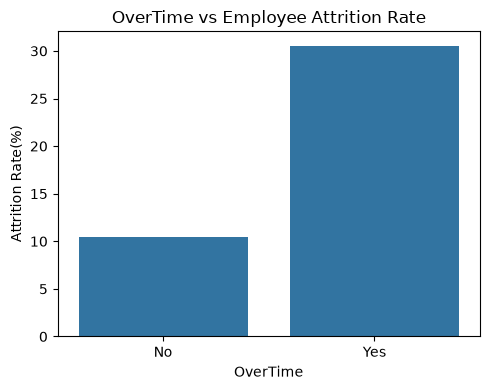

In [39]:
plt.figure(figsize=(5,4))
sns.barplot(x= OverTime_summary.index, y=OverTime_summary['Attrition_Rate'])
plt.title('OverTime vs Employee Attrition Rate')
plt.xlabel('OverTime')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [42]:
BusinessTravel_summary = df.groupby('BusinessTravel').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
BusinessTravel_summary['Attrition_Rate'] = (BusinessTravel_summary['employees_left']/BusinessTravel_summary['total_employees']*100).round(2)
print(BusinessTravel_summary)

                   total_employees  employees_left  Attrition_Rate
BusinessTravel                                                    
Non-Travel                     150              12            8.00
Travel_Frequently              277              69           24.91
Travel_Rarely                 1043             156           14.96


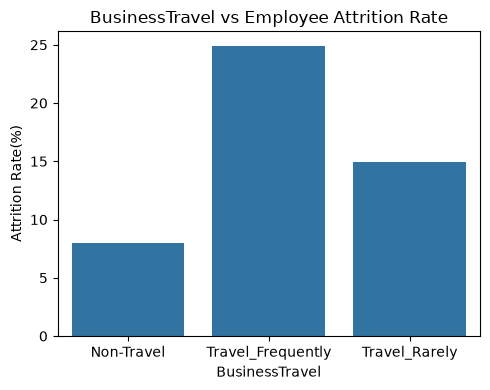

In [44]:
plt.figure(figsize=(5,4))
sns.barplot(x= BusinessTravel_summary.index, y=BusinessTravel_summary['Attrition_Rate'])
plt.title('BusinessTravel vs Employee Attrition Rate')
plt.xlabel('BusinessTravel')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [45]:
JobSatisfaction_summary = df.groupby('JobSatisfaction').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
JobSatisfaction_summary['Attrition_Rate'] = (JobSatisfaction_summary['employees_left']/JobSatisfaction_summary['total_employees']*100).round(2)
print(JobSatisfaction_summary)

                 total_employees  employees_left  Attrition_Rate
JobSatisfaction                                                 
1                            289              66           22.84
2                            280              46           16.43
3                            442              73           16.52
4                            459              52           11.33


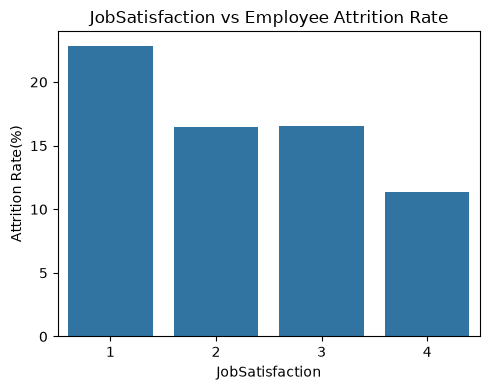

In [46]:
plt.figure(figsize=(5,4))
sns.barplot(x= JobSatisfaction_summary.index, y=JobSatisfaction_summary['Attrition_Rate'])
plt.title('JobSatisfaction vs Employee Attrition Rate')
plt.xlabel('JobSatisfaction')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [47]:
WorkLifeBalance_summary = df.groupby('WorkLifeBalance').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
WorkLifeBalance_summary['Attrition_Rate'] = (WorkLifeBalance_summary['employees_left']/WorkLifeBalance_summary['total_employees']*100).round(2)
print(WorkLifeBalance_summary)

                 total_employees  employees_left  Attrition_Rate
WorkLifeBalance                                                 
1                             80              25           31.25
2                            344              58           16.86
3                            893             127           14.22
4                            153              27           17.65


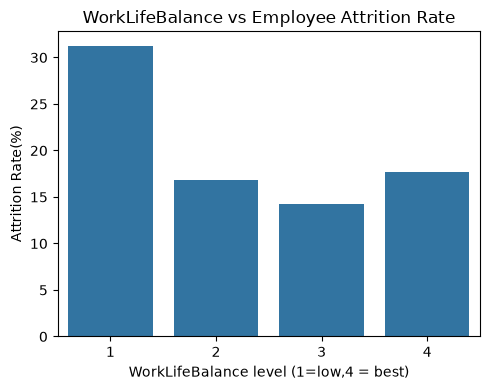

In [49]:
plt.figure(figsize=(5,4))
sns.barplot(x= WorkLifeBalance_summary.index, y=WorkLifeBalance_summary['Attrition_Rate'])
plt.title('WorkLifeBalance vs Employee Attrition Rate')
plt.xlabel('WorkLifeBalance level (1=low,4 = best)')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [52]:
df['Tenure_Group']= pd.cut(
    df['YearsAtCompany'],
    bins=[-1,1,5,10,20,40],
    labels=['0-1 Year','2-5 Year','6-10 Year','11-20 Year','21-40 Year'])
Tenure_summary = df.groupby('Tenure_Group').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
Tenure_summary['Attrition_Rate'] = (Tenure_summary['employees_left']/Tenure_summary['total_employees']*100).round(2)
print(Tenure_summary)

              total_employees  employees_left  Attrition_Rate
Tenure_Group                                                 
0-1 Year                  215              75           34.88
2-5 Year                  561              87           15.51
6-10 Year                 448              55           12.28
11-20 Year                180              12            6.67
21-40 Year                 66               8           12.12


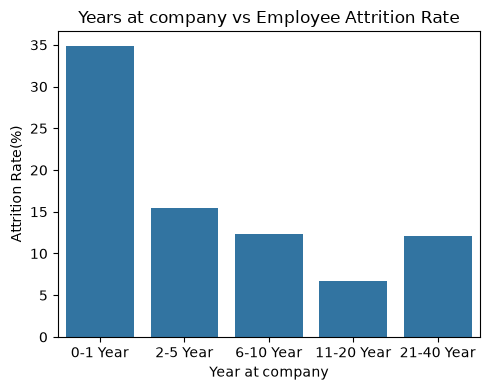

In [53]:
plt.figure(figsize=(5,4))
sns.barplot(x= Tenure_summary.index, y=Tenure_summary['Attrition_Rate'])
plt.title('Years at company vs Employee Attrition Rate')
plt.xlabel('Year at company')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [54]:
YearsInCurrentRole_summary = df.groupby('YearsInCurrentRole').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
YearsInCurrentRole_summary['Attrition_Rate'] = (YearsInCurrentRole_summary['employees_left']/YearsInCurrentRole_summary['total_employees']*100).round(2)
print(YearsInCurrentRole_summary)

                    total_employees  employees_left  Attrition_Rate
YearsInCurrentRole                                                 
0                               244              73           29.92
1                                57              11           19.30
2                               372              68           18.28
3                               135              16           11.85
4                               104              15           14.42
5                                36               1            2.78
6                                37               2            5.41
7                               222              31           13.96
8                                89               7            7.87
9                                67               6            8.96
10                               29               2            6.90
11                               22               0            0.00
12                               10             

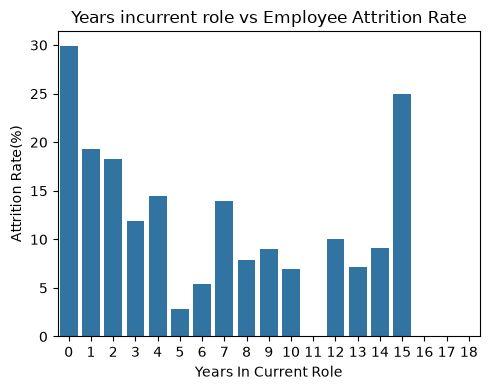

In [55]:
plt.figure(figsize=(5,4))
sns.barplot(x= YearsInCurrentRole_summary.index, y=YearsInCurrentRole_summary['Attrition_Rate'])
plt.title('Years incurrent role vs Employee Attrition Rate')
plt.xlabel('Years In Current Role')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [56]:
promotion_summary = df.groupby('YearsSinceLastPromotion').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
promotion_summary['Attrition_Rate'] = (promotion_summary['employees_left']/promotion_summary['total_employees']*100).round(2)
print(promotion_summary)

                         total_employees  employees_left  Attrition_Rate
YearsSinceLastPromotion                                                 
0                                    581             110           18.93
1                                    357              49           13.73
2                                    159              27           16.98
3                                     52               9           17.31
4                                     61               5            8.20
5                                     45               2            4.44
6                                     32               6           18.75
7                                     76              16           21.05
8                                     18               0            0.00
9                                     17               4           23.53
10                                     6               1           16.67
11                                    24           

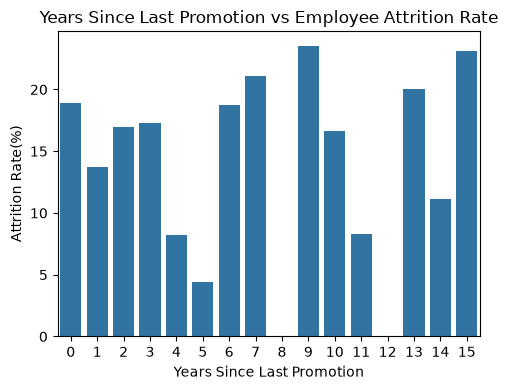

In [60]:
plt.figure(figsize=(5,4))
sns.barplot(x= promotion_summary.index, y=promotion_summary['Attrition_Rate'])
plt.title('Years Since Last Promotion vs Employee Attrition Rate')
plt.xlabel('Years Since Last Promotion')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [58]:
education_summary = df.groupby('Education').agg(total_employees=('Attrition','count'), employees_left=('Attrition',lambda x: (x =='Yes').sum()))
education_summary['Attrition_Rate'] = (education_summary['employees_left']/education_summary['total_employees']*100).round(2)
print(education_summary)

           total_employees  employees_left  Attrition_Rate
Education                                                 
1                      170              31           18.24
2                      282              44           15.60
3                      572              99           17.31
4                      398              58           14.57
5                       48               5           10.42


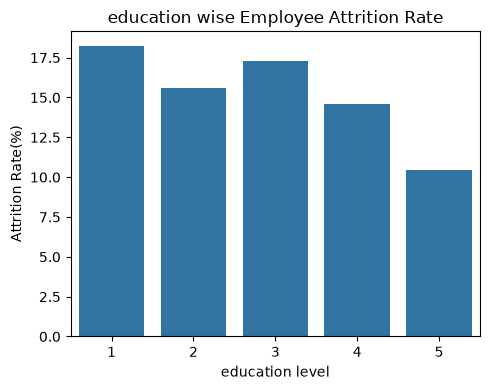

In [61]:
plt.figure(figsize=(5,4))
sns.barplot(x= education_summary.index, y=education_summary['Attrition_Rate'])
plt.title('education wise Employee Attrition Rate')
plt.xlabel('education level')
plt.ylabel('Attrition Rate(%)')
plt.tight_layout()
plt.show()

In [63]:
total_employee = len(df)
employees_left = (df['Attrition']=='Yes').sum()
active_employees = (df['Attrition']=='No').sum()
attrition_rate = round((employees_left/total_employee)*100,2)
print("HR EMPLOYEE ATTRITION SUMMARY")
print("-------------------------------")
print("total employee:",total_employee)
print("employees left:",employees_left)
print("active_employees:",active_employees)
print("Attrition Rate:",round(attrition_rate,2),"%")

HR EMPLOYEE ATTRITION SUMMARY
-------------------------------
total employee: 1470
employees left: 237
active_employees: 1233
Attrition Rate: 16.12 %


In [73]:
Correlation_Data = df.copy()

Correlation_Data['Attrition'] = (
    Correlation_Data['Attrition'].map({'Yes': 1, 'No': 0})
)

Correlation_matrix = Correlation_Data.select_dtypes(
    include ='number'
).corr()

print(Correlation_matrix['Attrition'].sort_values(ascending=False))


Attrition                   1.000000
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
EmployeeNumber             -0.010577
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
DailyRate                  -0.056652
TrainingTimesLastYear      -0.059478
WorkLifeBalance            -0.063939
EnvironmentSatisfaction    -0.103369
JobSatisfaction            -0.103481
JobInvolvement             -0.130016
YearsAtCompany             -0.134392
StockOptionLevel           -0.137145
YearsWithCurrManager       -0.156199
Age                        -0.159205
MonthlyIncome              -0.159840
YearsInCurrentRole         -0.160545
JobLevel                   -0.169105
TotalWorkingYears          -0.171063
EmployeeCount                    NaN
StandardHours                    NaN
N

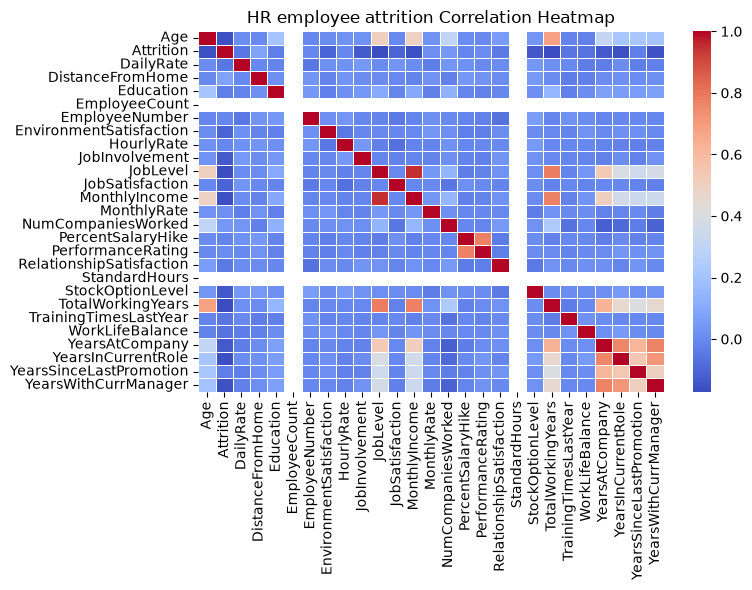

In [77]:
plt.figure(figsize=(8,6))
sns.heatmap(Correlation_matrix,
           cmap='coolwarm',
           annot=False,
           linewidths=0.5
           )
plt.title('HR employee attrition Correlation Heatmap')
plt.tight_layout()
plt.show()